In [1]:
# Install required geospatial libraries in Google Colab
!pip install geopy folium scikit-learn pandas numpy matplotlib seaborn -q

import os
import pandas as pd
import numpy as np
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Set the path to your CSV file in Google Drive
# UPDATE THIS PATH if your file is in a specific folder (e.g., '/content/drive/MyDrive/GPS_Data/gps_data.csv')
file_path = '/content/drive/MyDrive/gps_data.csv'

# Check if file exists in Drive
if os.path.exists(file_path):
    print(f"File found successfully at: {file_path}")
else:
    print(f"File not found at '{file_path}'. Please verify the filename and folder path in your Google Drive.")

Mounted at /content/drive
File found successfully at: /content/drive/MyDrive/gps_data.csv


In [2]:
print("--- Step 1: Loading & Cleaning Raw GPS Data from Drive ---")

# 1. Load Data from Google Drive (Handles CSVs with or without headers)
df_raw = pd.read_csv(file_path, header=None)

# Check if the first row contains text headers or raw data
if str(df_raw.iloc[0, 0]).lower() in ['date', 'timestamp']:
    df = pd.read_csv(file_path)
else:
    df = pd.read_csv(file_path, header=None, names=["Date", "Time", "Latitude", "Longitude", "Speed"])

print(f"Initial raw record count: {len(df)}")

# 2. Inspect missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# 3. Data Type Conversions & Handling Missing Values
df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')
df['Speed'] = pd.to_numeric(df['Speed'], errors='coerce')

# Drop rows with invalid coordinates
df.dropna(subset=['Latitude', 'Longitude'], inplace=True)

# Clean speed anomalies (remove negative values or unrealistic GPS spikes > 150 km/h)
df = df[(df['Speed'] >= 0.0) & (df['Speed'] <= 150.0)]

# 4. Construct Timestamp Datetime Index
df['Datetime'] = pd.to_datetime(df['Date'].astype(str) + ' ' + df['Time'].astype(str))
df.sort_values(by='Datetime', inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"\nCleaned record count: {len(df)}")
print(df.head())

--- Step 1: Loading & Cleaning Raw GPS Data from Drive ---
Initial raw record count: 3002

Missing values per column:
Date         0
Time         0
Latitude     0
Longitude    0
Speed        0
dtype: int64

Cleaned record count: 3002
         Date      Time   Latitude  Longitude  Speed            Datetime
0  2026-10-28  09:07:39  26.863578  81.021160   0.54 2026-10-28 09:07:39
1  2026-10-28  09:08:51  26.863560  81.021148   0.24 2026-10-28 09:08:51
2  2026-10-28  09:09:57  26.863608  81.021175   0.15 2026-10-28 09:09:57
3  2026-10-28  09:10:36  26.863513  81.021182   0.37 2026-10-28 09:10:36
4  2026-10-28  09:11:17  26.863487  81.021177   0.31 2026-10-28 09:11:17


In [3]:
from geopy.distance import geodesic

print("--- Step 2: Feature Engineering & Distance Metrics ---")

# Calculate step-by-step distances in meters using GeoPy
distances_m = [0.0]
time_diffs_sec = [0.0]

for i in range(1, len(df)):
    prev_point = (df.loc[i-1, 'Latitude'], df.loc[i-1, 'Longitude'])
    curr_point = (df.loc[i, 'Latitude'], df.loc[i, 'Longitude'])

    # Geodesic distance in meters
    dist = geodesic(prev_point, curr_point).meters
    distances_m.append(dist)

    # Time delta in seconds
    t_diff = (df.loc[i, 'Datetime'] - df.loc[i-1, 'Datetime']).total_seconds()
    time_diffs_sec.append(t_diff)

df['Distance_Meters'] = distances_m
df['Time_Delta_Sec'] = time_diffs_sec
df['Cumulative_Distance_KM'] = df['Distance_Meters'].cumsum() / 1000.0

# Extract Hour of Day
df['Hour'] = df['Datetime'].dt.hour

total_dist_km = df['Cumulative_Distance_KM'].iloc[-1]
print(f"Total Distance Traveled: {total_dist_km:.2f} km")

--- Step 2: Feature Engineering & Distance Metrics ---
Total Distance Traveled: 56.93 km


In [4]:
from sklearn.cluster import DBSCAN

print("--- Step 3: Spatial Clustering (Discovering Places) ---")

# Filter for low-speed points (Stop Points / Dwell Locations)
stop_points = df[df['Speed'] < 3.0].copy()

# Convert Lat/Lng to Radians for Haversine distance matrix
coords_rad = np.radians(stop_points[['Latitude', 'Longitude']].to_numpy())

# DBSCAN Parameters
kms_per_radian = 6371.0088
eps_rad = (0.1) / kms_per_radian

# Min samples = 10 continuous fixes (~5 minutes of stopping)
db = DBSCAN(eps=eps_rad, min_samples=10, metric='haversine')
stop_points['Cluster'] = db.fit_predict(coords_rad)

# Map clusters back to the main DataFrame (-1 = Transit / Moving)
df['Cluster'] = -1
df.loc[stop_points.index, 'Cluster'] = stop_points['Cluster']

# Summarize Discovered Clusters
clusters_summary = stop_points[stop_points['Cluster'] != -1].groupby('Cluster').agg(
    Center_Lat=('Latitude', 'mean'),
    Center_Lng=('Longitude', 'mean'),
    Reading_Count=('Latitude', 'count'),
    Start_Time=('Datetime', 'min'),
    End_Time=('Datetime', 'max')
).reset_index()

# Automatically assign semantic names based on correct cluster IDs
semantic_names = {0: "Home", 1: "Print Shop", 2: "University"}
clusters_summary['Location_Name'] = clusters_summary['Cluster'].map(semantic_names).fillna("Frequent Spot")

print(clusters_summary[['Cluster', 'Location_Name', 'Center_Lat', 'Center_Lng', 'Reading_Count']])

--- Step 3: Spatial Clustering (Discovering Places) ---
   Cluster Location_Name  Center_Lat  Center_Lng  Reading_Count
0        0          Home   26.863493   81.021301           2017
1        1    Print Shop   26.951659   81.100277             79
2        2    University   26.952863   81.096937            366


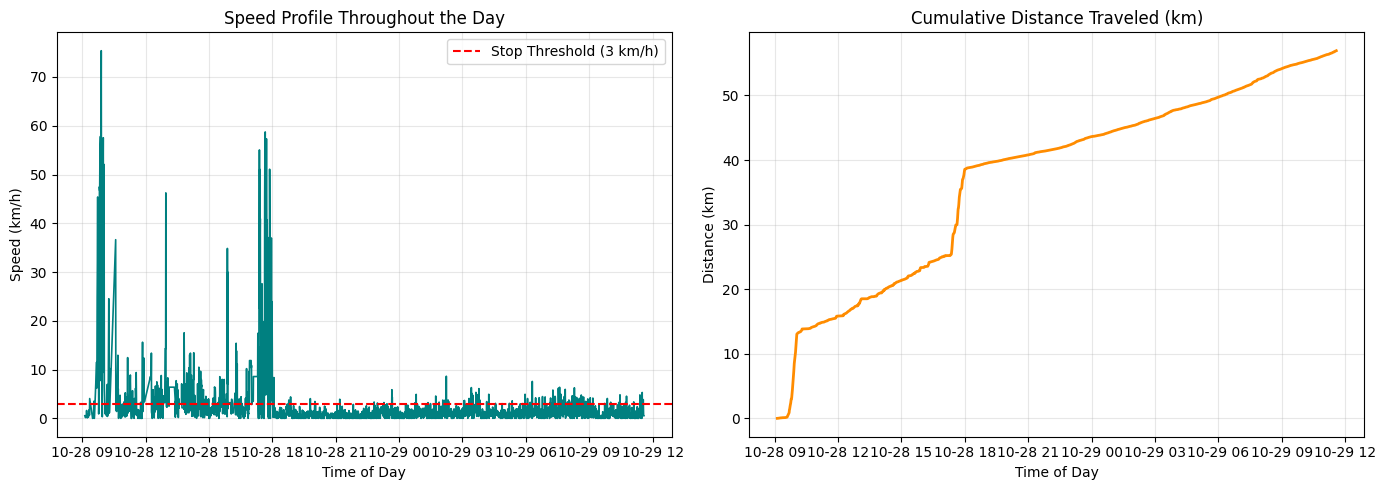

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 5))

# Plot 1: Speed Profile over Time
plt.subplot(1, 2, 1)
plt.plot(df['Datetime'], df['Speed'], color='teal', linewidth=1.2)
plt.axhline(y=3.0, color='r', linestyle='--', label='Stop Threshold (3 km/h)')
plt.title('Speed Profile Throughout the Day')
plt.xlabel('Time of Day')
plt.ylabel('Speed (km/h)')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Cumulative Distance Traveled
plt.subplot(1, 2, 2)
plt.plot(df['Datetime'], df['Cumulative_Distance_KM'], color='darkorange', linewidth=2)
plt.title('Cumulative Distance Traveled (km)')
plt.xlabel('Time of Day')
plt.ylabel('Distance (km)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
import folium

print("--- Rendering OpenStreetMap Inline ---")

# 1. Center map on average coordinates
center_lat = df['Latitude'].mean()
center_lng = df['Longitude'].mean()

# 2. Initialize map using explicit OpenStreetMap tile endpoint & attribution
m = folium.Map(
    location=[df['Latitude'].mean(), df['Longitude'].mean()],
    zoom_start=15,
    tiles=None
)
# Esri Street layer
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri Street"
).add_to(m)

# Satellite layer
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri, Maxar, Earthstar Geographics",
    name="Satellite"
).add_to(m)

# Layer switch button
folium.LayerControl(collapsed=False).add_to(m)

# 3. Plot Trajectory Polyline
path_coords = df[['Latitude', 'Longitude']].values.tolist()
folium.PolyLine(
    locations=path_coords,
    color='blue',
    weight=4,
    opacity=0.8,
    tooltip="1-Day Trajectory Path"
).add_to(m)

# 4. Add Cluster Markers (Home, University, Print Shop)
color_map = {"Home": "green", "University": "red", "Print Shop": "purple"}

for _, row in clusters_summary.iterrows():
    loc_name = row['Location_Name']
    marker_color = color_map.get(loc_name, "orange")

    popup_text = f"""
    <b>Location:</b> {loc_name}<br>
    <b>Center Lat:</b> {row['Center_Lat']:.5f}<br>
    <b>Center Lng:</b> {row['Center_Lng']:.5f}<br>
    <b>Total Fixes:</b> {row['Reading_Count']}
    """

    folium.Marker(
        location=[row['Center_Lat'], row['Center_Lng']],
        popup=folium.Popup(popup_text, max_width=300),
        tooltip=loc_name,
        icon=folium.Icon(color=marker_color, icon='info-sign')
    ).add_to(m)

# 5. Display directly in Google Colab output cell
m

--- Rendering OpenStreetMap Inline ---


In [7]:
print("======================================================")
print("              GPS TRAJECTORY INSIGHTS REPORT          ")
print("======================================================")
print(f"1. Total Distance Covered   : {total_dist_km:.2f} km")
print(f"2. Total Recorded Duration  : {(df['Datetime'].max() - df['Datetime'].min()).total_seconds()/3600:.2f} Hours")
print(f"3. Maximum Speed Achieved   : {df['Speed'].max():.2f} km/h")
print(f"4. Average Moving Speed     : {df[df['Speed'] >= 3.0]['Speed'].mean():.2f} km/h")
print(f"5. Total Discovered Places  : {len(clusters_summary)} ({', '.join(clusters_summary['Location_Name'].tolist())})")
print("======================================================")

              GPS TRAJECTORY INSIGHTS REPORT          
1. Total Distance Covered   : 56.93 km
2. Total Recorded Duration  : 26.45 Hours
3. Maximum Speed Achieved   : 75.39 km/h
4. Average Moving Speed     : 9.95 km/h
5. Total Discovered Places  : 3 (Home, Print Shop, University)
